<a href="https://colab.research.google.com/github/danielamsnsilva/ML26/blob/master/M1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("/diabetes_risk.csv")    #https://www.kaggle.com/datasets/mansiaggarwal88/diabetes-risk-prediction/data

df.columns = df.columns.str.strip() #remove os espaços em branco no início e no fim dos nomes

# Limpeza inicial das strings
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

df.replace(r"^\s*$", np.nan, regex=True, inplace=True)   #substituir células vazias ou que contêm apenas espaços em branco por valores NaN
df.replace("?", np.nan, inplace=True)

print("Dimensão do dataset:", df.shape)
print("\nPrimeiras linhas:")
print(df.head(4))

print("\nInformação geral:")
df.info()

print("\nEstatísticas descritivas:")
print(df.describe(include="all"))

Dimensão do dataset: (15000, 19)

Primeiras linhas:
   patient_id  age  gender       city   bmi family_history_diabetes  \
0           1   47  Female     Mumbai  26.5                     Yes   
1           2   53  Female     Mumbai  20.5                     Yes   
2           3   47    Male      Thane  31.3                      No   
3           4   41    Male  Bengaluru  22.8                      No   

  physical_activity_level       diet_type smoking_status alcohol_consumption  \
0               Sedentary      Vegetarian          Never               Never   
1                Moderate      Vegetarian          Never               Never   
2                Moderate  Non-Vegetarian        Current             Regular   
3               Sedentary  Non-Vegetarian          Never               Never   

   hours_sleep_per_night  stress_level  fasting_blood_sugar  hba1c_level  \
0                    9.0             8                  178          7.3   
1                    7.0             6 


Valores em falta:
patient_id                     0
age                            0
gender                         0
city                           0
bmi                            0
family_history_diabetes        0
physical_activity_level        0
diet_type                      0
smoking_status               472
alcohol_consumption         3788
hours_sleep_per_night          0
stress_level                   0
fasting_blood_sugar            0
hba1c_level                    0
blood_pressure_systolic        0
blood_pressure_diastolic       0
waist_circumference_cm         0
income_bracket               463
diabetes_risk                  0
dtype: int64

Registos duplicados: 0

Tipos de atributos:
patient_id                    int64
age                           int64
gender                       object
city                         object
bmi                         float64
family_history_diabetes      object
physical_activity_level      object
diet_type                    object
smoking_

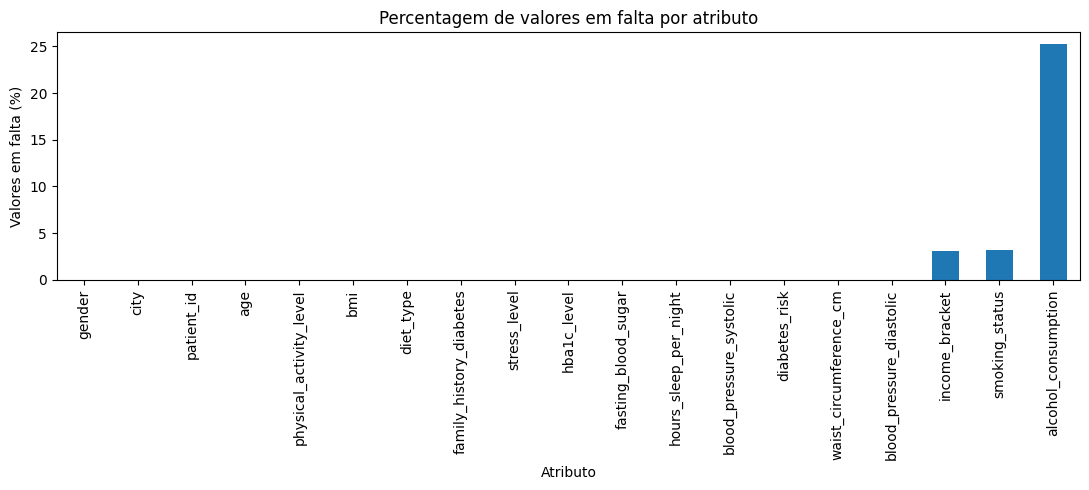

In [ ]:

#qualiade dos dadosa

print("\nValores em falta:")
print(df.isnull().sum())

print("\nRegistos duplicados:", df.duplicated().sum())

print("\nTipos de atributos:")
print(df.dtypes)


Emfalta = pd.DataFrame({"Emfalta": df.isnull().sum(),"Percentagem (%)": (df.isnull().mean() * 100).round(2)}).sort_values("Percentagem (%)", ascending=False)

print("\nValores em falta:")
print(Emfalta)

# Visualização dos valores em falta
plt.figure(figsize=(11, 5))
Emfalta["Percentagem (%)"].sort_values().plot(kind="bar")
plt.title("Percentagem de valores em falta por atributo")
plt.xlabel("Atributo")
plt.ylabel("Valores em falta (%)")
plt.tight_layout()
plt.show()

In [ ]:
#AED

target = "diabetes_risk"

print("Dimensão:", df.shape)
print("\nClasses:")
print(df[target].value_counts(dropna=False))
print(df.head())

numeric = df.select_dtypes(include=np.number).columns

print("\nNúmero de valores distintos:")
print(df.nunique().sort_values())

print("\nEstatísticas numéricas:")
print(df[numeric].describe().T)



Dimensão: (15000, 19)

Classes:
diabetes_risk
Low         9000
Moderate    3750
High        2250
Name: count, dtype: int64
   patient_id  age  gender       city   bmi family_history_diabetes  \
0           1   47  Female     Mumbai  26.5                     Yes   
1           2   53  Female     Mumbai  20.5                     Yes   
2           3   47    Male      Thane  31.3                      No   
3           4   41    Male  Bengaluru  22.8                      No   
4           5   57  Female  Bengaluru  16.7                      No   

  physical_activity_level       diet_type smoking_status alcohol_consumption  \
0               Sedentary      Vegetarian          Never               Never   
1                Moderate      Vegetarian          Never               Never   
2                Moderate  Non-Vegetarian        Current             Regular   
3               Sedentary  Non-Vegetarian          Never               Never   
4               Sedentary  Non-Vegetarian        C

In [ ]:
#pre processamentos

if "patient_id" in df.columns:   #tirar o patient_id
    df = df.drop(columns=["patient_id"])
# se o objetivo do nosso trabalho é a predição do risco de diabetes, é necessário dar drop à coluna diabetes_risk
if "diabetes_risk" in df.columns:
    df = df.drop(columns=["diabetes_risk"])

In [ ]:
#data transformation pipeline
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer

#Transformation - vamos selecionar o dados por data type
numeric = df.select_dtypes(include=np.number).columns
categorical = df.select_dtypes(include="object").columns

#processement
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")), #todo - verificar se é a estratégia mais correcta a adoptar
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")), #todo - verificar se é a estratégia mais correcta a adoptar
    ("encoder", OneHotEncoder(handle_unknown="ignore")) #todo
])

#Column Transformer - joins the preprocessement for numeric and categorical pipelines in a ColumnTransformer
pipeline = ColumnTransformer([
    ("num", StandardScaler(), numeric_pipeline),
    ("cat", OneHotEncoder(), categorical_pipeline)
])

df_prep = pipeline.fit_transform(df) #data transformation step






